# Which way does each property face? A walkthrough on Castlecrag

This notebook runs the `property_orientation` method on one suburb: Castlecrag, in Willoughby
LGA, Sydney. Each G-NAF address is matched to the OpenStreetMap street named in its address,
and the property is taken to face the nearest point on that street. The result is then checked
against an independent reference from the NSW cadastre: the direction in which each parcel's
street frontage faces.

**Before you run it:** download the inputs once with `make data` (or `property-orientation
fetch`). They are saved in `data/raw/willoughby/`. The notebook works from the repository root
or from `notebooks/`.

In [1]:
from __future__ import annotations

from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyproj
import shapely
from IPython.display import Markdown, display
from matplotlib import patheffects
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

from property_orientation import (
    COMPASS_8,
    angular_difference,
    compass8,
    compute_orientation,
    gnaf_street_key,
    normalise_street_name,
    validation,
)
from property_orientation.config import Paths, StudyArea
from property_orientation.orientation import FRONTAGE_HIGHWAYS, prepare_roads
from property_orientation.reference import reference_orientation
from property_orientation.viz import style


def find_repo_root(start: Path) -> Path:
    """The nearest folder at or above ``start`` that holds this repository."""
    for folder in (start, *start.parents):
        if (folder / "src" / "property_orientation").is_dir():
            return folder
    raise FileNotFoundError("Run this notebook from inside the property-orientation repository.")


ROOT = find_repo_root(Path.cwd())
paths = Paths(root=ROOT, area=StudyArea())  # Willoughby LGA, NSW
if not paths.raw_file("addresses").exists():
    raise FileNotFoundError(f"No inputs in {paths.raw}: run `make data` first.")

CRS = 7856  # GDA2020 / MGA zone 56: metres, for distances and maps
style.apply()
plt.rcParams["figure.dpi"] = 110
pd.options.display.float_format = "{:,.1f}".format

## 1. Inputs

| Layer | Source | Role |
|---|---|---|
| `addresses` | G-NAF (Geoscape) | address points, with street name, type and suffix as separate fields |
| `osm_highways` | OpenStreetMap | every `highway=*` way: streets, footpaths, steps, driveways |
| `nsw_property` | NSW cadastre (DCDB) | property parcels (validation only) |
| `nsw_road_reserve` | NSW cadastre | road reserve polygons (validation only) |
| `nsw_road_centreline` | NSW cadastre | road centrelines, most of them named (validation only) |

Castlecrag's streets follow the contours and many houses back onto footpath reserves, which
makes it a hard test for any method that faces the nearest line on a map. Its addresses are
those with `locality_name == "CASTLECRAG"`. The other layers are cut to Castlecrag's bounding box
plus 500 m. That margin covers the 250 m street search radius and the 500 m radius of the
original nearest-way method, so the results below match the full Willoughby run (checked at the
end).

In [2]:
LAYERS = ("addresses", "osm_highways", "nsw_property", "nsw_road_reserve", "nsw_road_centreline")
downloaded = {name: gpd.read_parquet(paths.raw_file(name)).to_crs(CRS) for name in LAYERS}

addresses = downloaded["addresses"].query("locality_name == 'CASTLECRAG'")
xmin, ymin, xmax, ymax = addresses.total_bounds + np.array([-500, -500, 500, 500])
roads, parcels, road_reserves, centrelines = (
    downloaded[name].cx[xmin:xmax, ymin:ymax] for name in LAYERS[1:]
)
subset = dict(zip(LAYERS, (addresses, roads, parcels, road_reserves, centrelines), strict=True))

pd.DataFrame(
    {
        "Willoughby download": [f"{len(downloaded[name]):,}" for name in LAYERS],
        "Castlecrag subset": [f"{len(subset[name]):,}" for name in LAYERS],
    },
    index=pd.Index(LAYERS, name="features"),
)

,Willoughby download,Castlecrag subset
features,,
addresses,"43,551","1,216"
osm_highways,"14,659",979
nsw_property,"90,859","4,139"
nsw_road_reserve,"7,172",459
nsw_road_centreline,"4,160",306


A few Castlecrag addresses. `primary_secondary` is `S` for a unit within a complex.
`geocode_type` says what the point marks; in Castlecrag it is almost always the property
centroid, a point inside the land parcel.

In [3]:
columns = ["address", "street_name", "street_type", "street_suffix", "primary_secondary"]
addresses.sample(5, random_state=4).set_index("gnaf_pid")[[*columns, "geocode_type"]]

,address,street_name,street_type,street_suffix,primary_secondary,geocode_type
gnaf_pid,,,,,,
GANSW704373015,15 RUTLAND AVENUE,RUTLAND,AVENUE,NaN,NaN,PROPERTY CENTROID
GANSW704355780,38 THE RAMPART,THE RAMPART,NaN,NaN,NaN,PROPERTY CENTROID
GANSW704341170,15 SUNNYSIDE CRESCENT,SUNNYSIDE,CRESCENT,NaN,NaN,PROPERTY CENTROID
GANSW704360764,99 THE BULWARK,THE BULWARK,NaN,NaN,NaN,PROPERTY CENTROID
GANSW704351770,"UNIT 2, 7 THE PARAPET",THE PARAPET,NaN,NaN,S,PROPERTY CENTROID


## 2. Street names

The three sources spell the same street differently. `normalise_street_name` maps each
spelling to one key: upper case, punctuation removed, and an abbreviated road type or suffix at
the end expanded (`RD W` becomes `ROAD WEST`); a leading `SAINT` becomes `ST`.
`gnaf_street_key` does the same from G-NAF's separate name, type and suffix fields. These
spellings all occur in the downloaded data.

In [4]:
spellings = [
    # (G-NAF name, type, suffix), OpenStreetMap name, NSW centreline label
    (("EDINBURGH", "ROAD", None), "Edinburgh Road", "EDINBURGH RD"),
    (("SUGARLOAF", "CRESCENT", None), "Sugarloaf Crescent", "SUGARLOAF CR"),
    (("THE PARAPET", None, None), "The Parapet", "THE PARAPET"),
    (("MOWBRAY", "ROAD", "WEST"), "Mowbray Road West", "MOWBRAY RD W"),
]
rows = []
for gnaf, osm_name, nsw_label in spellings:
    keys = {gnaf_street_key(*gnaf), *map(normalise_street_name, (osm_name, nsw_label))}
    assert len(keys) == 1, keys  # all three spellings give the same key
    rows.append(
        {
            "G-NAF name · type · suffix": " · ".join(part or "–" for part in gnaf),
            "OpenStreetMap": osm_name,
            "NSW centreline": nsw_label,
            "normalised key": keys.pop(),
        }
    )
pd.DataFrame(rows)

,G-NAF name · type · suffix,OpenStreetMap,NSW centreline,normalised key
0,EDINBURGH · ROAD · –,Edinburgh Road,EDINBURGH RD,EDINBURGH ROAD
1,SUGARLOAF · CRESCENT · –,Sugarloaf Crescent,SUGARLOAF CR,SUGARLOAF CRESCENT
2,THE PARAPET · – · –,The Parapet,THE PARAPET,THE PARAPET
3,MOWBRAY · ROAD · WEST,Mowbray Road West,MOWBRAY RD W,MOWBRAY ROAD WEST


## 3. Orientation

`compute_orientation` works in four steps:

1. Addresses at the same point, on the same street and with the same geocode type, such as
   the units in one building, are grouped into a **site**. Each site is computed once.
2. Each site is matched to the OSM way that carries its street's name: the full name first,
   then the name with a suffix such as `WEST` dropped from one side only, then the bare name
   without a road type. Two different suffixes (`EAST` and `WEST`) never match.
   Ways a property can front (streets, pedestrian streets and named lanes) win over footpaths
   with the same name (OSM has a footway called Edinburgh Road, for example). With no named match within 250 m, the nearest street a property can
   front is used instead.
3. The site faces the **nearest point on that way**. The bearing is the geodesic azimuth from
   the site to that point, in degrees from true north, binned into eight 45° sectors.
4. **Confidence** is `high` for a name match within 60 m, not geocoded to a building centroid,
   with no differently named street closer; `medium` for a name match within 120 m; `low`
   otherwise, and always when the match dropped a suffix that G-NAF has (G-NAF's
   `MARKET STREET EAST` is a separate street from OSM's `Market Street`). Sites with no street within 250 m, geocoded to the street or suburb rather
   than the property, or lying within 0.5 m of the street line, get `none`.

It also computes the original method, the nearest OSM way of any class, for comparison.

In [5]:
result = compute_orientation(addresses, roads, crs=CRS)
sites = result.sites
print(f"{len(addresses):,} addresses → {len(sites):,} sites")

columns = ["street_key", "n_addresses", "matched_street", "match", "distance_m", "bearing_deg"]
sites[[*columns, "orientation", "confidence"]].head()

1,216 addresses → 1,116 sites


,street_key,n_addresses,matched_street,match,distance_m,bearing_deg,orientation,confidence
site_id,,,,,,,,
0,SUGARLOAF CRESCENT,1,Sugarloaf Crescent,street_name,30.0,159.3,S,high
1,SUGARLOAF CRESCENT,1,Sugarloaf Crescent,street_name,33.2,230.1,SW,high
2,SUGARLOAF CRESCENT,1,Sugarloaf Crescent,street_name,27.3,227.0,SW,high
3,SUGARLOAF CRESCENT,1,Sugarloaf Crescent,street_name,26.0,22.2,N,high
4,SUGARLOAF CRESCENT,1,Sugarloaf Crescent,street_name,32.7,203.5,SW,high


In [6]:
breakdown = pd.crosstab(sites["match"], sites["confidence"], margins=True, margins_name="all")
breakdown.reindex(columns=["high", "medium", "low", "none", "all"], fill_value=0)

confidence,high,medium,low,none,all
match,,,,,
nearest_street,0,0,1,0,1
street_name,971,136,5,3,1115
all,971,136,6,3,1116


Nearly every site matches its street by full name. Sites with `none` are geocoded to the
street itself (`STREET LOCALITY`), so they get no bearing; `low` sites are more than 120 m from
their street, use the nearest-street fallback, or dropped a G-NAF street suffix.

## 4. One block, two methods

The Parapet and The Rampart are two curved streets with a footpath reserve between the backs
of their houses. Each arrow runs from an address site to the point the method faces, coloured by
its 8-point direction. The original method faces whichever OSM way is closest, and here that is
often the footpath behind the house.

In [7]:
BLOCK = ["THE PARAPET", "THE RAMPART"]
HALF_SIZE_M = 140  # a 280 m square centred on the two streets' sites
FOOTPATHS = ["footway", "path", "steps"]

block = sites[sites["street_key"].isin(BLOCK)]
cx, cy = block["x"].mean(), block["y"].mean()
window = shapely.box(cx - HALF_SIZE_M, cy - HALF_SIZE_M, cx + HALF_SIZE_M, cy + HALF_SIZE_M)

to_geographic = pyproj.Transformer.from_crs(CRS, pyproj.CRS(CRS).geodetic_crs, always_xy=True)
geod = pyproj.Geod(ellps="GRS80")


def point_along(
    x: np.ndarray, y: np.ndarray, bearing_deg: np.ndarray, distance_m: np.ndarray
) -> tuple[np.ndarray, np.ndarray]:
    """Map coordinates ``distance_m`` from (x, y) along a true bearing (used for drawing)."""
    lon, lat = to_geographic.transform(x, y)
    lon2, lat2, _ = geod.fwd(lon, lat, bearing_deg, distance_m)
    return to_geographic.transform(lon2, lat2, direction="INVERSE")


# The baseline reports a bearing and a distance; rebuild the point it faced to draw its arrow.
arrows = sites[sites["bearing_deg"].notna()].copy()
arrows["baseline_x"], arrows["baseline_y"] = point_along(
    arrows["x"].to_numpy(),
    arrows["y"].to_numpy(),
    arrows["baseline_bearing_deg"].to_numpy(),
    arrows["baseline_distance_m"].to_numpy(),
)
inner = window.buffer(-4)
fits = np.logical_and.reduce(
    [
        shapely.contains_xy(inner, arrows[x].to_numpy(), arrows[y].to_numpy())
        for x, y in [("x", "y"), ("street_x", "street_y"), ("baseline_x", "baseline_y")]
    ]
)
view = arrows[fits]

# Base map: parcels, and OSM ways split into streets a property can front and everything else.
osm = prepare_roads(roads[roads.intersects(window.buffer(80))])
is_street = osm["frontage"] | osm["highway"].isin(["motorway", "motorway_link"])
streets, other_ways = osm[is_street], osm[~is_street]
lots = parcels[parcels.intersects(window.buffer(80))]
names = " and ".join(street.title() for street in BLOCK)
print(f"{len(view)} sites drawn in a {2 * HALF_SIZE_M} m square around {names}")

61 sites drawn in a 280 m square around The Parapet and The Rampart


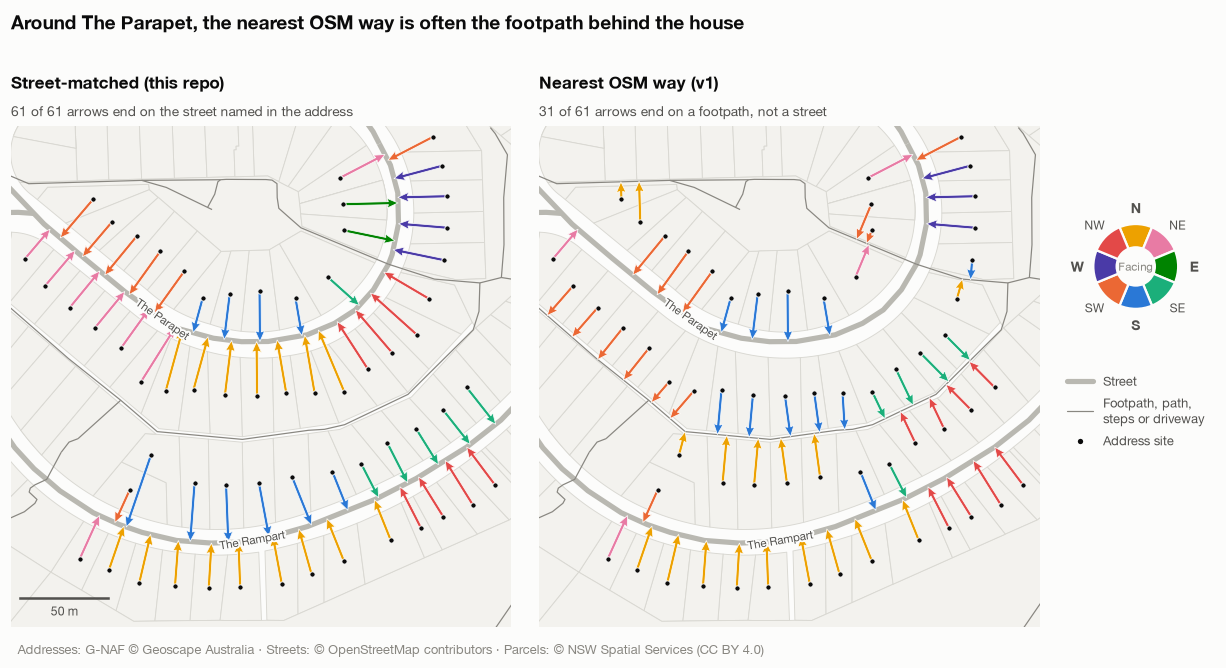

In [8]:
def label_street(ax: plt.Axes, lines: gpd.GeoSeries, name: str, avoid: np.ndarray) -> None:
    """Write a street name along its centreline, where it is clearest of the arrows."""
    pieces = lines.intersection(window.buffer(-15))
    parts = shapely.get_parts(shapely.line_merge(shapely.union_all(pieces.to_numpy())))
    if not len(parts) or max(parts, key=shapely.length).length < 40:
        return  # too little of this street in view to carry a label
    line = max(parts, key=shapely.length)
    fractions = np.linspace(0.15, 0.85, 29)
    candidates = shapely.line_interpolate_point(line, fractions, normalized=True)
    clearance = shapely.distance(candidates[:, None], shapely.points(avoid)[None, :]).min(axis=1)
    best = fractions[np.argmax(clearance)]
    ends = shapely.line_interpolate_point(line, [best - 0.03, best + 0.03], normalized=True)
    (x0, y0), (x1, y1) = shapely.get_coordinates(ends)
    angle = (np.degrees(np.arctan2(y1 - y0, x1 - x0)) + 90) % 180 - 90  # keep text upright
    x, y = shapely.get_coordinates(candidates[np.argmax(clearance)])[0]
    halo = patheffects.withStroke(linewidth=2.5, foreground=style.SURFACE)
    ax.text(x, y, name, rotation=angle, rotation_mode="anchor", ha="center", va="center",
            fontsize=7.5, color=style.INK_SECONDARY, zorder=6, path_effects=[halo])  # fmt: skip


n = len(view)
n_named = int(view["match"].ne("nearest_street").sum())
n_footpath = int(view["baseline_highway"].isin(FOOTPATHS).sum())
panels = {
    "street_matched": ("street_x", "street_y", "orientation",
                       f"{n_named} of {n} arrows end on the street named in the address"),
    "nearest_road": ("baseline_x", "baseline_y", "baseline_orientation",
                     f"{n_footpath} of {n} arrows end on a footpath, not a street"),
}  # fmt: skip
tips = [view[[x, y]].to_numpy() for x, y, _, _ in panels.values()]
avoid = np.vstack([*tips, view[["x", "y"]].to_numpy()])  # keep street labels clear of these

fig = plt.figure(figsize=(11, 6.2))
inch = np.tile(fig.get_size_inches(), 2)
map_axes = [fig.add_axes(np.array((left, 0.35, 4.55, 4.55)) / inch) for left in (0.05, 4.85)]
for ax, (method, (x_col, y_col, label_col, subtitle)) in zip(map_axes, panels.items(), strict=True):
    lots.plot(ax=ax, facecolor=style.PARCEL_FILL, edgecolor=style.PARCEL_EDGE, linewidth=0.6)
    streets.plot(ax=ax, color=style.ROAD, linewidth=3.4)
    other_ways.plot(ax=ax, color=style.INK_MUTED, linewidth=0.8)
    x, y = view["x"].to_numpy(), view["y"].to_numpy()
    u, v = view[x_col].to_numpy() - x, view[y_col].to_numpy() - y
    ax.quiver(x, y, u, v, color=style.direction_colors(view[label_col]), angles="xy",
              scale_units="xy", scale=1, width=0.006, headwidth=3.2, headlength=3.6,
              headaxislength=3.2, edgecolor=style.SURFACE, linewidth=0.5, zorder=4)  # fmt: skip
    ax.scatter(x, y, s=12, color=style.INK, edgecolor=style.SURFACE, linewidth=0.6, zorder=5)
    for name in view["matched_street"].dropna().unique():
        label_street(ax, streets.geometry[streets["name"].eq(name)], name, avoid)
    ax.set(xlim=window.bounds[::2], ylim=window.bounds[1::2], aspect="equal")
    ax.set_axis_off()
    ax.text(0, 1.075, style.METHOD_LABELS[method], transform=ax.transAxes, fontsize=11,
            fontweight="bold", color=style.INK)  # fmt: skip
    ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9, color=style.INK_SECONDARY)
scale_bar = AnchoredSizeBar(map_axes[0].transData, 50, "50 m", loc="lower left", frameon=False,
                            pad=0.6, sep=3, size_vertical=0.8, color=style.INK_SECONDARY,
                            fontproperties={"size": 8})  # fmt: skip
map_axes[0].add_artist(scale_bar)

style.compass_legend(fig.add_axes(np.array((9.6, 2.95, 1.35, 1.35)) / inch))
key = fig.add_axes(np.array((9.6, 1.5, 1.4, 1.2)) / inch)
key.axis("off")
handles = [
    Line2D([], [], color=style.ROAD, linewidth=3.4, label="Street"),
    Line2D([], [], color=style.INK_MUTED, linewidth=0.8,
           label="Footpath, path,\nsteps or driveway"),
    Line2D([], [], linestyle="none", marker="o", markersize=4.5, markerfacecolor=style.INK,
           markeredgecolor=style.SURFACE, label="Address site"),
]  # fmt: skip
key.legend(handles=handles, loc="upper left", borderaxespad=0, fontsize=8.5,
           labelcolor=style.INK_SECONDARY)  # fmt: skip
title = "Around The Parapet, the nearest OSM way is often the footpath behind the house"
fig.text(0.05 / inch[0], 1 - 0.25 / inch[1], title, fontsize=12.5, fontweight="bold",
         color=style.INK, va="top")  # fmt: skip
style.attribution(fig)
plt.show()

## 5. Validation against the cadastre

`reference_orientation` builds a reference bearing from the NSW cadastre. It shares only the
address point and its G-NAF street name with the method; parcels, road reserves and NSW
centrelines are independent of OpenStreetMap.

1. Find the parcel that contains the site.
2. Keep the parts of its boundary that run along a road reserve: the **frontage**.
3. Take the outward normal of each frontage segment, from the parcel into the road.
4. Name each segment after the first NSW centreline its normal crosses within 40 m.
5. Average the normals of the frontage onto the addressed street, weighted by length.

Sites with no parcel, no frontage onto their street, less than 3 m of it, or a frontage whose
normals cancel out get no reference. `compare_methods` then scores both methods on the same
sites.

In [9]:
reference = reference_orientation(sites, parcels, road_reserves, centrelines)
sites = sites.join(reference)
sites["ref_status"].value_counts().rename("sites").to_frame()

,sites
ref_status,
ok,1017
no_street_frontage,74
short_frontage,22
no_parcel,3


In [10]:
AGREEMENT = {
    "same_8_point_direction": "same 8-point direction",
    "within_22_5_deg": "within 22.5°",
    "within_45_deg": "within 45°",
    "median_error_deg": "median error",
    "p90_error_deg": "90th percentile error",
}


def agreement_table(table: pd.DataFrame, index: str) -> pd.DataFrame:
    """Agreement statistics for reading: shares as percentages and errors in degrees."""
    out = pd.DataFrame({"sites": table["sites"].map("{:,}".format)})
    for column, title in AGREEMENT.items():
        template = "{:.1f}°" if column.endswith("error_deg") else "{:.1%}"
        out[title] = table[column].map(template.format)
    return out.set_axis(table[index].to_numpy())


comparison = validation.compare_methods(sites)
agreement_table(comparison.assign(method=comparison["method"].map(style.METHOD_LABELS)), "method")

,sites,same 8-point direction,within 22.5°,within 45°,median error,90th percentile error
Street-matched (this repo),"1,017",89.5%,94.5%,97.5%,1.8°,13.1°
Nearest OSM way (v1),"1,017",64.2%,67.9%,71.0%,3.4°,155.3°


In [11]:
stats = comparison.set_index("method")
evaluated = validation.evaluation_set(sites)
baseline_error = angular_difference(evaluated["baseline_bearing_deg"], evaluated["ref_bearing_deg"])
not_a_street = ~evaluated["baseline_highway"].isin(sorted(FRONTAGE_HIGHWAYS - {"service"}))
display(
    Markdown(
        f"Street matching gives the cadastre's 8-point direction for "
        f"**{stats.loc['street_matched', 'same_8_point_direction']:.0%}** of these sites, "
        f"against **{stats.loc['nearest_road', 'same_8_point_direction']:.0%}** for the nearest "
        f"OSM way; {not_a_street[baseline_error > 45].mean():.0%} of the nearest way's errors "
        f"over 45° come from facing an OSM way that is not a street, such as a footpath, steps "
        f"or a driveway."
    )
)

Street matching gives the cadastre's 8-point direction for **89%** of these sites, against **64%** for the nearest OSM way; 84% of the nearest way's errors over 45° come from facing an OSM way that is not a street, such as a footpath, steps or a driveway.

## 6. Which way does Castlecrag face?

A rose diagram of the facing bearings in 15° bins. Each 45° compass sector spans three bins,
so a bin's colour is its 8-point direction. The same diagram for every site in Willoughby,
read from the published results, is shown for comparison.

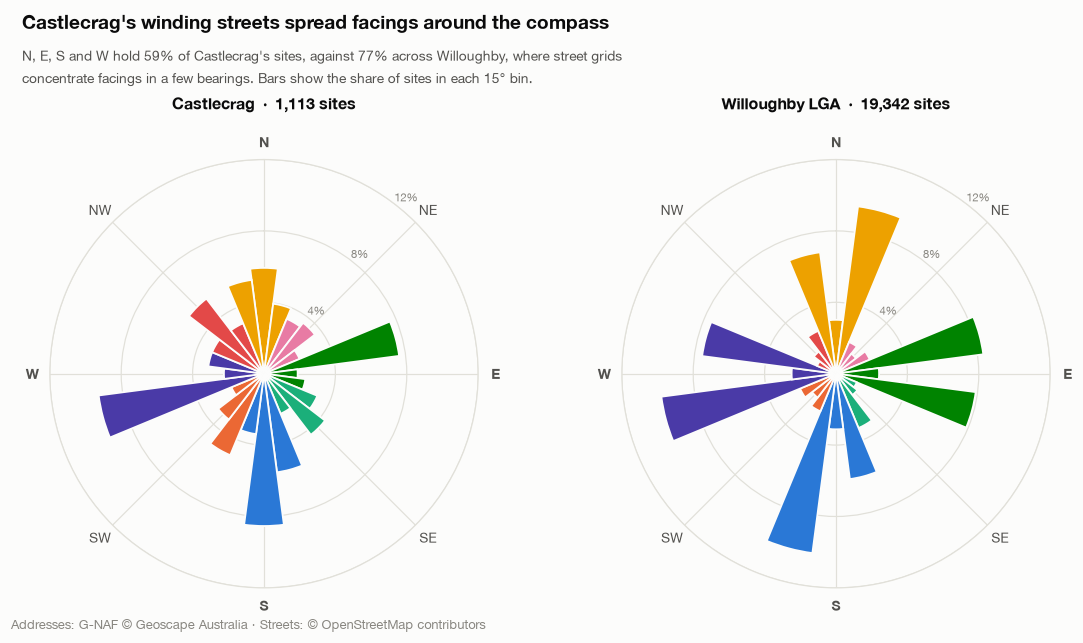

In [12]:
BIN_DEG = 15
centres = np.arange(0, 360, BIN_DEG)
colours = style.direction_colors(compass8(centres))


def bin_shares(bearings: pd.Series) -> np.ndarray:
    """Share of bearings in each bin; bins are centred on 0°, 15°, 30° and so on."""
    values = bearings.dropna().to_numpy()
    k = (np.mod(values + BIN_DEG / 2, 360) // BIN_DEG).astype(int)
    return np.bincount(k, minlength=len(centres)) / len(values)


def cardinal_share(bearings: pd.Series) -> float:
    """Share of bearings in the N, E, S and W sectors."""
    return float(np.isin(compass8(bearings.dropna()), ["N", "E", "S", "W"]).mean())


published = pd.read_csv(paths.results / "property_orientation.csv")
bearings = {
    "Castlecrag": sites["bearing_deg"],
    "Willoughby LGA": published.drop_duplicates("site_id")["bearing_deg"],
}
shares = {name: bin_shares(values) for name, values in bearings.items()}
r_max = np.ceil(max(s.max() for s in shares.values()) / 0.04) * 0.04
rings = np.arange(0.04, r_max + 1e-9, 0.04)

fig, axes = plt.subplots(1, 2, figsize=(10, 5.9), subplot_kw={"projection": "polar"})
fig.subplots_adjust(left=0.04, right=0.96, top=0.74, bottom=0.08, wspace=0.3)
for ax, (name, share) in zip(axes, shares.items(), strict=True):
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.bar(np.radians(centres), share, width=np.radians(BIN_DEG), color=colours,
           edgecolor=style.SURFACE, linewidth=1.2, zorder=3)  # fmt: skip
    ax.set_ylim(0, r_max)
    ax.set_yticks(rings, labels=[f"{r:.0%}" for r in rings])
    ax.set_rlabel_position(37.5)
    ax.tick_params(axis="y", labelsize=7.5, labelcolor=style.INK_MUTED)
    ax.set_xticks(np.radians(np.arange(0, 360, 45)), labels=COMPASS_8)
    ax.tick_params(axis="x", labelsize=9, labelcolor=style.INK_SECONDARY, pad=1)
    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold" if len(tick.get_text()) == 1 else "normal")
    ax.grid(color=style.GRID, linewidth=0.8)
    ax.spines["polar"].set_color(style.GRID)
    ax.set_title(f"{name}  ·  {bearings[name].notna().sum():,} sites", loc="center",
                 fontsize=10.5, pad=16)  # fmt: skip

cc, lga = (cardinal_share(values) for values in bearings.values())
title = "Castlecrag's winding streets spread facings around the compass"
subtitle = (
    f"N, E, S and W hold {cc:.0%} of Castlecrag's sites, against {lga:.0%} across Willoughby, "
    "where street grids\nconcentrate facings in a few bearings. Bars show the share of sites "
    "in each 15° bin."
)
fig.text(0.02, 0.97, title, fontsize=12.5, fontweight="bold", color=style.INK, va="top")
fig.text(0.02, 0.915, subtitle, fontsize=9, color=style.INK_SECONDARY, va="top", linespacing=1.4)
style.attribution(
    fig, "Addresses: G-NAF © Geoscape Australia · Streets: © OpenStreetMap contributors"
)
plt.show()

## 7. Limitations

- **Building centroids on large sites.** Apartment blocks, retirement villages and other large
  sites are often geocoded to a building centroid, well inside the parcel. The bearing from that
  point to the nearest part of the street need not match the site's frontage, so these sites are
  never `high` confidence.
- **Corner lots.** A corner house may face the other street, not the one in its address. The
  method follows the address. Sites where a differently named street is closer are capped at
  `medium` confidence.
- **Streets missing from OpenStreetMap.** When the addressed street is not in OSM, or has no
  name there, the nearest street a property can front is used and the site is `low`
  confidence. A site is also `low` when OSM has only the unsuffixed street of the same name
  (G-NAF `MARKET STREET EAST`, OSM `Market Street`): it is matched to that street, but the
  suffixed street is often a separate one. Low-confidence sites agree with the cadastre far less often (second table below).
- **A property faces its street by assumption.** The bearing says which way the street
  frontage faces. It does not capture a house turned towards a view or set at an angle on
  its lot.

## 8. Full results for Willoughby

`make run` writes the same analysis for the whole LGA to `results/willoughby/`:
`property_orientation.csv` (one row per address), `property_orientation.gpkg` (addresses,
facing lines, suburbs), `summary_by_suburb.csv`, `summary_orientation.csv`, `run_summary.json`
and the validation tables in `validation/`. The tables below are read from
`validation/method_comparison.csv` and `validation/by_confidence.csv`: the two methods on every
Willoughby site with both a bearing and a cadastral reference, and street matching by confidence class.

In [13]:
lga_methods = pd.read_csv(paths.validation / "method_comparison.csv")
lga_methods = lga_methods.assign(method=lga_methods["method"].map(style.METHOD_LABELS))
display(agreement_table(lga_methods, "method"))
by_confidence = pd.read_csv(paths.validation / "by_confidence.csv")
order = ["high", "medium", "low"]
agreement_table(by_confidence.set_index("confidence").loc[order].reset_index(), "confidence")

,sites,same 8-point direction,within 22.5°,within 45°,median error,90th percentile error
Street-matched (this repo),"18,193",93.3%,96.8%,98.5%,0.5°,8.1°
Nearest OSM way (v1),"18,193",64.9%,67.2%,69.4%,1.5°,121.2°


,sites,same 8-point direction,within 22.5°,within 45°,median error,90th percentile error
high,"12,349",95.0%,98.2%,99.5%,0.5°,5.3°
medium,"5,683",91.0%,95.1%,97.9%,0.6°,12.2°
low,161,37.9%,45.3%,46.6%,72.1°,76.2°


In [14]:
# This notebook reproduces the published table for Castlecrag, address by address.
bearing = sites["bearing_deg"].to_numpy()[result.site_of_address]
ours = np.mod(pd.Series(bearing, index=addresses["gnaf_pid"]).round(1), 360)  # as published
theirs = published.set_index("gnaf_pid")["bearing_deg"].reindex(ours.index)
same = (ours - theirs).abs().le(0.05) | (ours.isna() & theirs.isna())
source = (paths.results / "property_orientation.csv").relative_to(ROOT)
print(f"{same.sum():,} of {len(same):,} Castlecrag addresses have the same bearing as {source}")

1,216 of 1,216 Castlecrag addresses have the same bearing as results/willoughby/property_orientation.csv
